In [1]:
import os
import time
import torch
import random
import numpy as np
import csv
from tqdm import tqdm

import torch
import math  # <-- Add this line
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder

from sklearn.metrics import classification_report


# =========================
# ✅ 调用你的模型
# =========================
from FMGFormer import FMGFormer

# =========================
# 🔒 关键：安全版 ImageFolder（过滤 .ipynb_checkpoints）
# =========================
class CleanImageFolder(ImageFolder):
    def find_classes(self, directory):
        classes = []
        for d in os.listdir(directory):
            full = os.path.join(directory, d)
            if os.path.isdir(full) and not d.startswith("."):
                classes.append(d)

        classes.sort()
        class_to_idx = {cls: i for i, cls in enumerate(classes)}
        return classes, class_to_idx


# =========================
# 🔒 固定：训练 / 验证函数
# =========================
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0

    for imgs, labels in tqdm(loader, desc="Train", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total += imgs.size(0)

    return total_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0

    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc="Eval", leave=False):
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)

    return total_loss / total, correct / total


# =========================
# 📁 数据路径
# =========================
data_root = "./datasets"
train_dir = os.path.join(data_root, "train")
val_dir   = os.path.join(data_root, "val")
test_dir  = os.path.join(data_root, "test")


# =========================
# ⚙️ 训练配置
# =========================
img_size = 224
num_classes = 7
batch_size = 32
num_epochs = 100
lr = 1e-4
num_workers = 10

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# =========================
# 🎲 固定随机种子
# =========================
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# =========================
# 🖼 数据增强
# =========================
train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])


# =========================
# 📦 Dataset & DataLoader
# =========================
train_ds = CleanImageFolder(train_dir, transform=train_transform)
val_ds   = CleanImageFolder(val_dir, transform=val_transform)
test_ds  = CleanImageFolder(test_dir, transform=val_transform)

print("Class mapping:", train_ds.class_to_idx)

# 🔒 类别数硬校验（非常重要）
assert len(train_ds.classes) == num_classes, \
    f"❌ 类别数不一致: dataset={len(train_ds.classes)} vs num_classes={num_classes}"

train_loader = DataLoader(
    train_ds, batch_size=batch_size,
    shuffle=True, num_workers=num_workers, pin_memory=True
)

val_loader = DataLoader(
    val_ds, batch_size=batch_size,
    shuffle=False, num_workers=num_workers, pin_memory=True
)

test_loader = DataLoader(
    test_ds, batch_size=batch_size,
    shuffle=False, num_workers=num_workers, pin_memory=True
)


# =========================
# ⭐ 模型
# =========================
model = FMGFormer(
    num_classes=num_classes
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=num_epochs
)

Using device: cuda
GPU: NVIDIA GeForce RTX 4090
Class mapping: {'Brown Blight': 0, 'Gray Blight': 1, 'Green mirid bug': 2, 'Healthy leaf': 3, 'Helopeltis': 4, 'Red spider': 5, 'Tea algal leaf spot': 6}


In [2]:
import torch
from thop import profile

# 确保模型在正确的设备上
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)  # 将模型移到设备

# 切换到评估模式
model.eval()

# 使用适当的 img_size
img_size = 224  # 可以根据实际输入尺寸调整
dummy_input = torch.randn(1, 3, img_size, img_size).to(device)

# 执行一次前向传播，确保模型的计算路径被启用
model(dummy_input)

# 计算 FLOPs 和参数量
flops, params = profile(model, inputs=(dummy_input,))

# 计算模型大小（MB）
model_size_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
model_size_mb = model_size_bytes / (1024 * 1024)  # 转换为MB

total_layers = len(list(model.modules()))

# 转换为百万 (M)
params_m = params / 1e6  

# 转换 FLOPs 为不同单位
flops_g = flops / 1e9  # 转换为吉浮点运算 (GFLOPs)
flops_m = flops / 1e6  # 转换为百万浮点运算 (MFLOPs)
flops_k = flops / 1e3  # 转换为千浮点运算 (KFLOPs)

# 打印总结信息
print(f"\nmodel summary: {total_layers} layers, "
      f"{params_m:.2f}M parameters, {params_m:.2f}M gradients, "
      f"{flops_g:.2f} GFLOPs, {flops_m:.1f} MFLOPs, {flops_k:.1f} KFLOPs, "
      f"{model_size_mb:.2f} MB model size")

[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv2d'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.batchnorm.BatchNorm2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.activation.ReLU'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.container.Sequential'>.
[INFO] Register count_adap_avgpool() for <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>.
[INFO] Register count_linear() for <class 'torch.nn.modules.linear.Linear'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.normalization.LayerNorm'>.
[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv1d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.dropout.Dropout'>.

model summary: 452 layers, 1.92M parameters, 1.92M gradients, 0.66 GFLOPs, 658.6 MFLOPs, 658638.1 KFLOPs, 7.35 MB model size


In [3]:

# ------------------- 保存目录 -------------------
os.makedirs('./Result/5/Train_csv', exist_ok=True)
os.makedirs('./Result/5/model_save', exist_ok=True)
csv_file = './Result/5/Train_csv/basel.csv'
best_model_path = os.path.join('./Result/5/model_save', 'best.pth')
last_model_path = os.path.join('./Result/5/model_save', 'last.pth')

# ------------------- resume_mode 配置 -------------------
resume_mode = "last"  # "last" / "best" / "none"
start_epoch = 1
best_val_acc = 0.0

if resume_mode.lower() == "last" and os.path.exists(last_model_path):
    checkpoint = torch.load(last_model_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    best_val_acc = checkpoint.get('best_val_acc', 0)
    print(f"✅ 从上次最新 checkpoint 继续训练：epoch {start_epoch}, best_val_acc={best_val_acc:.4f}")

elif resume_mode.lower() == "best" and os.path.exists(best_model_path):
    checkpoint = torch.load(best_model_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    best_val_acc = checkpoint.get('best_val_acc', 0)
    print(f"✅ 从最佳模型继续训练：epoch {start_epoch}, best_val_acc={best_val_acc:.4f}")

else:
    print("⚡ 从头开始训练")


# ------------------- 初始化 CSV -------------------
if not os.path.exists(csv_file):
    with open(csv_file, mode='w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc'])


# ------------------- 训练循环（完全未改） -------------------
for epoch in range(start_epoch, num_epochs + 1):
    t0 = time.time()

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )
    scheduler.step()

    print(f"[Epoch {epoch}/{num_epochs}] time:{time.time()-t0:.1f}s "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'train_loss': train_loss,
        'train_acc': train_acc,
        'val_loss': val_loss,
        'val_acc': val_acc,
        'best_val_acc': best_val_acc
    }, last_model_path)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'train_loss': train_loss,
            'train_acc': train_acc,
            'val_loss': val_loss,
            'val_acc': val_acc,
            'best_val_acc': best_val_acc
        }, best_model_path)

    with open(csv_file, mode='a', newline='') as f:
        writer = csv.writer(f)
        writer.writerow([epoch, train_loss, train_acc, val_loss, val_acc])

⚡ 从头开始训练


[Epoch 1/100] time:14.4s train_loss=1.6904 train_acc=0.2951 | val_loss=1.3988 val_acc=0.4580


[Epoch 2/100] time:14.4s train_loss=1.2949 train_acc=0.4833 | val_loss=1.1698 val_acc=0.5897


[Epoch 3/100] time:14.1s train_loss=1.1145 train_acc=0.5589 | val_loss=0.9872 val_acc=0.6317


[Epoch 4/100] time:13.3s train_loss=0.9522 train_acc=0.6341 | val_loss=0.8970 val_acc=0.6584


...

[Epoch 96/100] time:13.1s train_loss=0.0025 train_acc=0.9991 | val_loss=0.9809 val_acc=0.8416


[Epoch 97/100] time:12.6s train_loss=0.0035 train_acc=0.9984 | val_loss=0.9548 val_acc=0.8378


[Epoch 98/100] time:14.2s train_loss=0.0030 train_acc=0.9993 | val_loss=0.9865 val_acc=0.8321


[Epoch 99/100] time:14.4s train_loss=0.0042 train_acc=0.9987 | val_loss=0.9629 val_acc=0.8416


[Epoch 100/100] time:13.4s train_loss=0.0028 train_acc=0.9993 | val_loss=0.9822 val_acc=0.8359


In [5]:
# 获取类别到ID的映射字典
from sklearn.metrics import accuracy_score

id2name = {idx: cls for cls, idx in train_ds.class_to_idx.items()}
model.eval()
y_true_list, y_pred_probs_list = [], []

# 1. 收集模型预测和真实标签
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)
        outputs = model(imgs)  # Now expecting only the logits (not two outputs)
        probs = torch.softmax(outputs, dim=1)
        y_pred_probs_list.append(probs.cpu())
        y_true_list.append(labels.cpu())

y_pred_probs = torch.cat(y_pred_probs_list, dim=0)  # [num_samples, num_classes]
y_true = torch.cat(y_true_list, dim=0)             # [num_samples]

# 2. 预测类别
y_pred = torch.argmax(y_pred_probs, dim=1)

# =================== 平均置信度 ===================
confidence_scores = torch.max(y_pred_probs, dim=1).values  # 每个样本最大预测概率
avg_confidence_per_class = []

print("\n===== 平均置信度 =====")
for cls in range(num_classes):
    idxs = (y_true == cls)
    if idxs.sum() > 0:
        avg_conf = confidence_scores[idxs].mean().item()
    else:
        avg_conf = 0.0
    avg_confidence_per_class.append(avg_conf)
    print(f"Class {id2name.get(cls, str(cls))}: {avg_conf:.4f}")  # Print class name using id2name

# =================== 每类指标 ===================
tp, fp, fn = [], [], []

for cls in range(num_classes):
    tp_cls = ((y_pred == cls) & (y_true == cls)).sum().item()
    fp_cls = ((y_pred == cls) & (y_true != cls)).sum().item()
    fn_cls = ((y_pred != cls) & (y_true == cls)).sum().item()
    tp.append(tp_cls)
    fp.append(fp_cls)
    fn.append(fn_cls)

precision_per_class = [tp[i] / (tp[i] + fp[i]) if (tp[i] + fp[i]) > 0 else 0.0 for i in range(num_classes)]
recall_per_class = [tp[i] / (tp[i] + fn[i]) if (tp[i] + fn[i]) > 0 else 0.0 for i in range(num_classes)]
f1_per_class = [2 * p * r / (p + r) if (p + r) > 0 else 0.0 for p, r in zip(precision_per_class, recall_per_class)]

print("\n===== 每类指标 =====")
for cls in range(num_classes):
    print(f"Class {id2name.get(cls, str(cls))}: Precision={precision_per_class[cls]:.4f}, "
          f"Recall={recall_per_class[cls]:.4f}, F1={f1_per_class[cls]:.4f}")

# =================== 总体指标 ===================

accuracy = accuracy_score(
    y_true.numpy(),
    y_pred.numpy()
)

macro_precision = np.mean(precision_per_class)
macro_recall = np.mean(recall_per_class)
macro_f1 = np.mean(f1_per_class)


print("\n===== Overall Performance =====")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall: {macro_recall:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")


===== 平均置信度 =====
Class Brown Blight: 0.9293
Class Gray Blight: 0.9730
Class Green mirid bug: 0.9685
Class Healthy leaf: 0.9943
Class Helopeltis: 0.9661
Class Red spider: 0.9779
Class Tea algal leaf spot: 0.9337

===== 每类指标 =====
Class Brown Blight: Precision=0.8111, Recall=0.7087, F1=0.7565
Class Gray Blight: Precision=0.8273, Recall=0.8966, F1=0.8605
Class Green mirid bug: Precision=0.8803, Recall=0.8872, F1=0.8837
Class Healthy leaf: Precision=0.9892, Recall=0.9734, F1=0.9812
Class Helopeltis: Precision=0.8871, Recall=0.8943, F1=0.8907
Class Red spider: Precision=0.8667, Recall=0.8750, F1=0.8708
Class Tea algal leaf spot: Precision=0.7625, Recall=0.7176, F1=0.7394

===== Overall Performance =====
Accuracy: 0.8730
Macro Precision: 0.8606
Macro Recall: 0.8504
Macro F1-score: 0.8547


Test: 100%|██████████| 34/34 [00:02<00:00, 15.48it/s]


Confusion matrix saved to ./Result/5/confusion_matrix/confusion_matrix.tif


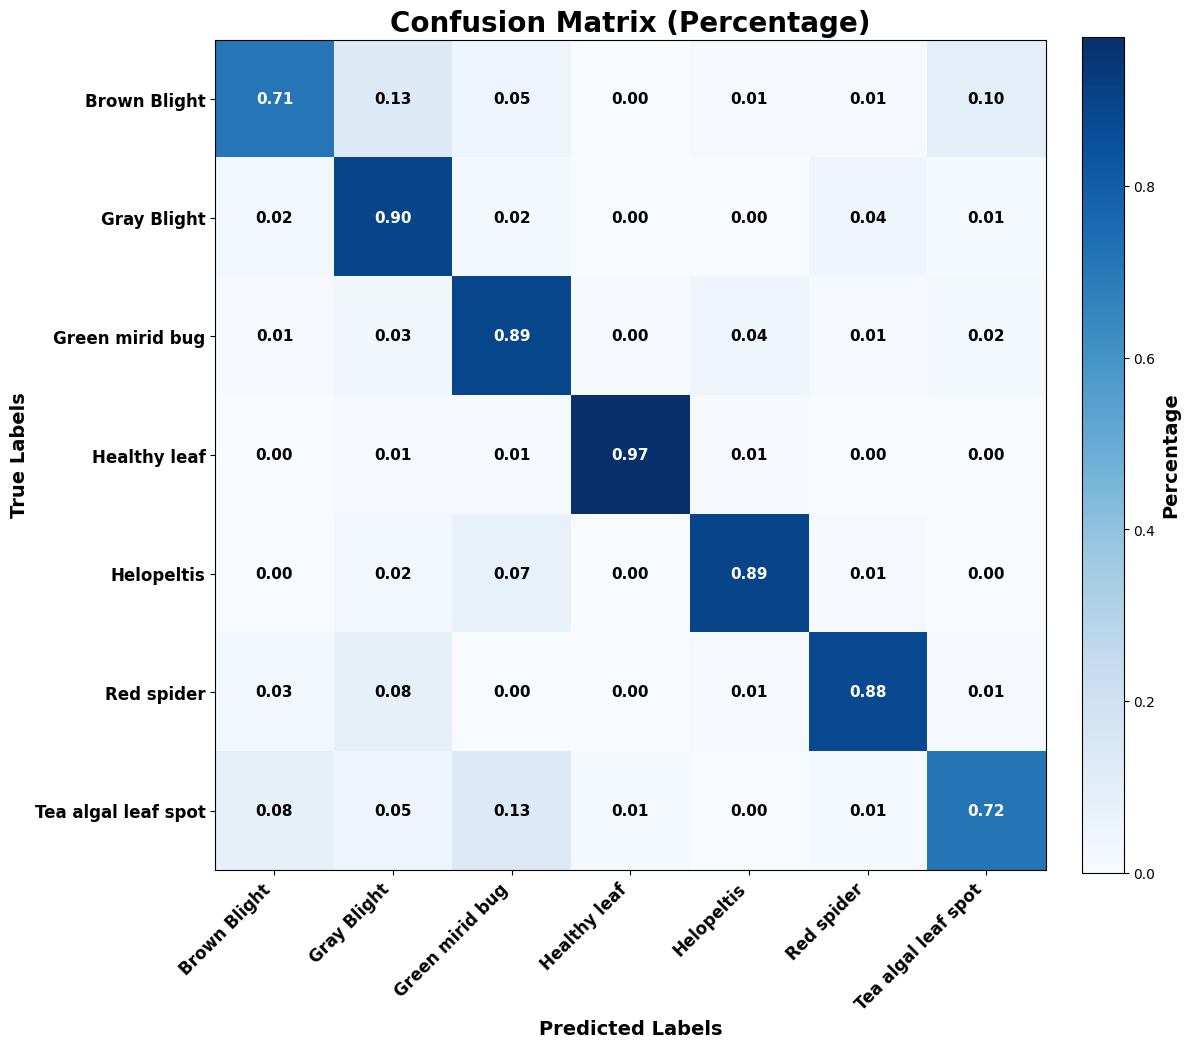

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 获取 class_names
class_names = train_ds.classes  # 从数据集中获取类名

# 1. 在推理时收集模型的预测结果
y_true_list = []  # 用于存储真实标签
y_pred_list = []  # 用于存储预测标签

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Test"):
        imgs = imgs.to(device)
        labels = labels.to(device)
        outputs = model(imgs)  # 预测 logits
        _, preds = torch.max(outputs, dim=1)  # 获取预测标签

        # 收集真实标签和预测标签
        y_true_list.append(labels.cpu())
        y_pred_list.append(preds.cpu())

# 2. 将 y_true_list 和 y_pred_list 转换为 numpy 数组（统一形状）
y_true_np = np.concatenate([x.numpy() for x in y_true_list], axis=0)
y_pred_np = np.concatenate([x.numpy() for x in y_pred_list], axis=0)

# 3. 计算百分比混淆矩阵
conf_matrix = confusion_matrix(y_true_np, y_pred_np, labels=range(num_classes))
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]

# 4. 保存路径
save_fig_dir = './Result/5/confusion_matrix'
os.makedirs(save_fig_dir, exist_ok=True)
fig_path = os.path.join(save_fig_dir, 'confusion_matrix.tif')

# 5. 画布
plt.figure(figsize=(12, 12))
im = plt.imshow(conf_matrix_percentage, interpolation='nearest', cmap='Blues')

# 标题
plt.title('Confusion Matrix (Percentage)', fontsize=20, weight='bold')

# colorbar
cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.set_label('Percentage', fontsize=14, weight='bold')

# 坐标轴
tick_marks = np.arange(num_classes)
plt.xticks(tick_marks, class_names, rotation=45, ha='right', fontsize=12, weight='bold')
plt.yticks(tick_marks, class_names, fontsize=12, weight='bold')
plt.xlabel('Predicted Labels', fontsize=14, weight='bold')
plt.ylabel('True Labels', fontsize=14, weight='bold')

# 6. 单元格数字：≥0.5 白字，<0.5 黑字，全部加粗
for i in range(num_classes):
    for j in range(num_classes):
        val = conf_matrix_percentage[i, j]
        plt.text(j, i, f'{val:.2f}',
                 ha='center', va='center',
                 fontsize=11, weight='bold',
                 color='white' if val >= 0.5 else 'black')

plt.grid(False)
plt.tight_layout()

# 7. 保存 & 显示
plt.savefig(fig_path, dpi=300, format='tif', bbox_inches='tight')
print(f'Confusion matrix saved to {fig_path}')
plt.show()